In [1]:
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

df = pd.read_csv("../data/raw/UserBehavior_sample.csv", names=["user_id","item_id","behavior_type","category_id","timestamp"])
df.head()


,user_id,item_id,behavior_type,category_id,timestamp
0,237858,1062152,1464116,pv,1512212331
1,44200,3916487,4135836,pv,1511931558
2,920479,2816757,154040,pv,1512311001
3,239462,2698818,154040,pv,1511783539
4,947273,3991295,1029459,pv,1512273837


In [8]:
# 时间戳转时间
df["dt"] = pd.to_datetime(df["timestamp"], unit="s")
df["date"] = df["dt"].dt.date
df["hour"] = df["dt"].dt.hour

# 过滤异常时间
start = pd.to_datetime("2017-11-25")
end = pd.to_datetime("2017-12-04")
df_clean = df[(df["dt"] >= start) & (df["dt"] < end)]
print("清洗前：", len(df))
print("清洗后：", len(df_clean))


清洗前： 1000000
清洗后： 987709


PV: 885259, UV: 524837
浏览用户: 490664
加购用户: 50774
支付用户: 19244
浏览→加购转化率: 6.58%
浏览→直接支付转化率（含跳过加购）: 2.28%
加购→支付转化率: 2.65%


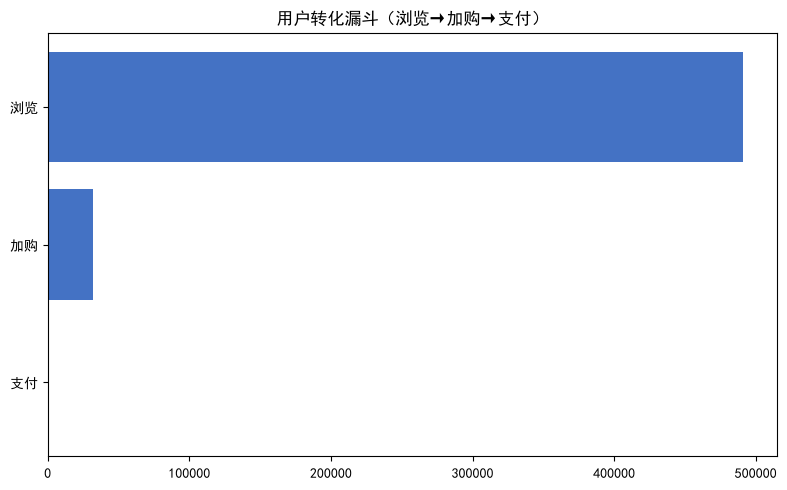

In [25]:
# PV UV
pv = len(df_clean[df_clean["category_id"] == "pv"])
uv = df_clean["user_id"].nunique()
print(f"PV: {pv}, UV: {uv}")

# 各环节用户集合
view_users = set(df_clean[df_clean["category_id"] == "pv"]["user_id"])
cart_users = set(df_clean[df_clean["category_id"] == "cart"]["user_id"])
buy_users = set(df_clean[df_clean["category_id"] == "buy"]["user_id"])

view_to_cart = cart_users & view_users
# 浏览、加购、支付三步都完成的用户
view_cart_buy = view_users & cart_users & buy_users
# 浏览过并且支付（可以跳过加购，直接下单）
view_to_buy = view_users & buy_users

print(f"浏览用户: {len(view_users)}")
print(f"加购用户: {len(cart_users)}")
print(f"支付用户: {len(buy_users)}")

# 转化率，加判断防止除0
if len(view_users) > 0:
    print(f"浏览→加购转化率: {len(view_to_cart)/len(view_users):.2%}")
    print(f"浏览→直接支付转化率（含跳过加购）: {len(view_to_buy)/len(view_users):.2%}")
else:
    print("浏览用户数为0，无法计算浏览相关转化率")

if len(cart_users) > 0:
    print(f"加购→支付转化率: {len(cart_users & buy_users)/len(cart_users):.2%}")
else:
    print("加购用户数为0，无法计算加购→支付转化率")

# 漏斗绘图：横向barh，从上到下：支付、加购、浏览
funnel_data = pd.DataFrame({
    "环节": ["支付", "加购", "浏览"],
    "用户数": [len(view_cart_buy), len(view_to_cart), len(view_users)]
})

plt.figure(figsize=(8,5))
plt.barh(funnel_data["环节"], funnel_data["用户数"], color="#4472C4")
plt.title("用户转化漏斗（浏览→加购→支付）")
plt.tight_layout()
plt.show()


In [16]:
#用户分群：首购/复购用户
buy_df = df_clean[df_clean["category_id"] == "buy"]
buy_cnt = buy_df.groupby("user_id").size().reset_index(name="buy_times")
buy_cnt["user_type"] = buy_cnt["buy_times"].apply(lambda x: "复购用户" if x>=2 else "首购用户")
print(buy_cnt["user_type"].value_counts())

repurchase_rate = (buy_cnt["user_type"]=="复购用户").sum() / len(buy_cnt)
print(f"整体复购率：{repurchase_rate:.2%}")



user_type
首购用户    18822
复购用户      422
Name: count, dtype: int64
整体复购率：2.19%


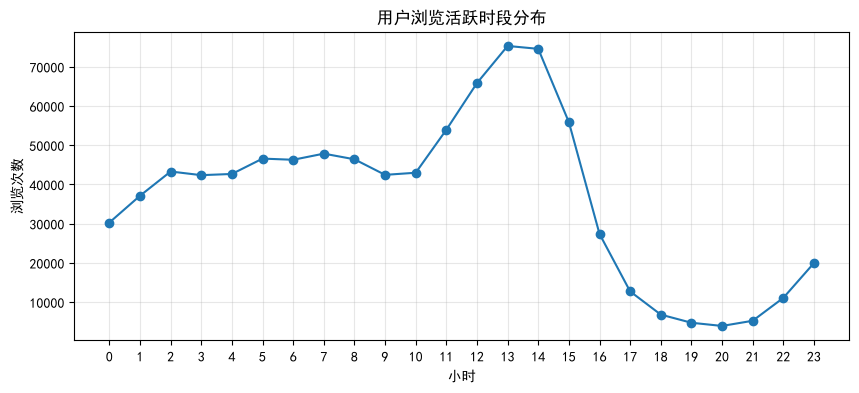

In [17]:
#活跃时段图
hour_pv = df_clean[df_clean["category_id"]=="pv"].groupby("hour").size()
plt.figure(figsize=(10,4))
plt.plot(hour_pv.index, hour_pv.values, marker="o")
plt.title("用户浏览活跃时段分布")
plt.xlabel("小时")
plt.ylabel("浏览次数")
plt.xticks(range(0,24))
plt.grid(alpha=0.3)
plt.show()


      behavior_type  buy_user  rep_user  rep_rate
712         1404020        21         1  0.047619
1619        3177877        22         1  0.045455
1608        3158249        71         3  0.042254
1340        2629787        26         1  0.038462
1865        3702593        26         1  0.038462
562         1074254        27         1  0.037037
1622        3189162        28         1  0.035714
453          901282        44         1  0.022727
390          800581        66         1  0.015152
196          381850        74         1  0.013514


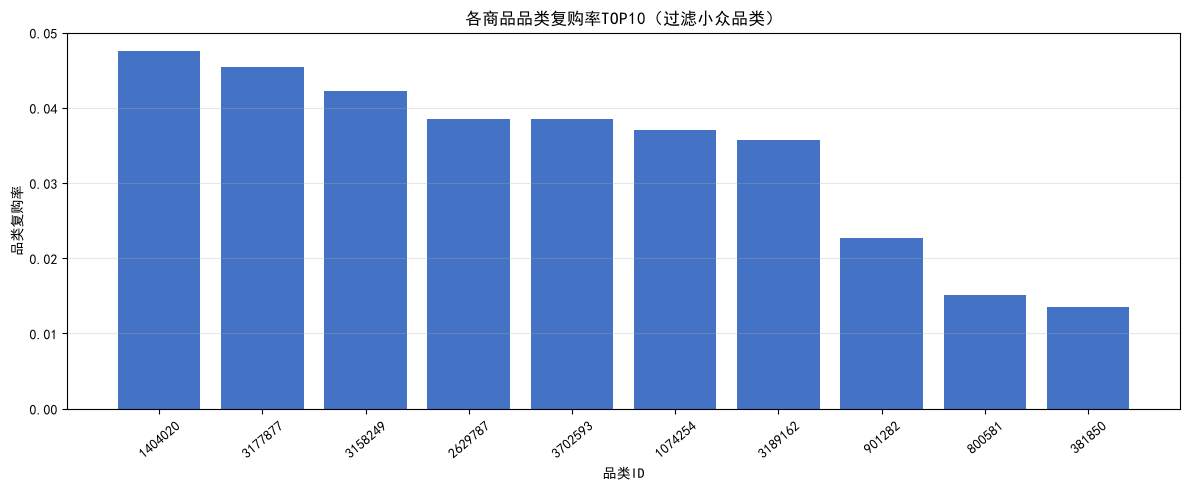

In [24]:
# 品类复购特征
buy_df = df_clean[df_clean["category_id"] == "buy"]

# 1. 每个用户在每个品类的购买次数
user_cat_buy = buy_df.groupby(["user_id","behavior_type"]).size().reset_index(name="buy_times")
# 标记该用户在这个品类是否复购（在该品类购买≥2次）
user_cat_buy["is_rep"] = user_cat_buy["buy_times"] >= 2

# 2. 按品类聚合：总购买用户数、该品类内复购用户数
cat_stat = user_cat_buy.groupby("behavior_type").agg(
    buy_user = ("user_id", "nunique"),
    rep_user = ("is_rep", "sum")
).reset_index()

# 3. 品类复购率
cat_stat["rep_rate"] = cat_stat["rep_user"] / cat_stat["buy_user"]

# 【新增】过滤小众品类
cat_stat = cat_stat[cat_stat["buy_user"] >= 20]

# 按复购率降序，取TOP10
cat_top10 = cat_stat.sort_values("rep_rate", ascending=False).head(10)
print(cat_top10)

# 可选：加上画图，论文图更好看
plt.figure(figsize=(12,5))
plt.bar(cat_top10["behavior_type"].astype(str), cat_top10["rep_rate"], color="#4472C4")
plt.title("各商品品类复购率TOP10（过滤小众品类）")
plt.xlabel("品类ID")
plt.ylabel("品类复购率")
plt.xticks(rotation=40)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
